# Trabajo 1 de Estadística Descriptiva
## Matrícula de Educación Superior, Región de Tarapacá (2021)

**Integrantes:** Catalina Arredondo, Bayron Cerda, Jean Darius, Fernando Catalán

### Caso de estudio

El equipo de orientación vocacional de un liceo de Iquique recibe la base de datos de la matrícula 2021 en educación superior de la Región de Tarapacá. Quiere usarla para orientar a sus estudiantes de cuarto medio y necesita responder tres cosas: **quiénes** se matriculan (edad), **dónde** lo hacen (tipo de institución) y **cuánto cuestan** las carreras (arancel), además de las preguntas de investigación del ítem 2.

### Objetivo general

Describir y analizar las características de la matrícula de educación superior de la Región de Tarapacá durante el año 2021, considerando variables cualitativas y cuantitativas, para identificar patrones y relaciones asociados al tipo de institución, la edad de los estudiantes y los aranceles de las carreras.

### Variables principales del análisis

| Variable | Clasificación | Uso |
|---|---|---|
| `TIPO DE INSTITUCION` | Cualitativa nominal | Variable cualitativa principal |
| `EDAD` | Cuantitativa continua (se registra en años cumplidos) | Variable cuantitativa principal |
| `AREA CONOCIMIENTO` | Cualitativa nominal | Ítem 2, pregunta 1 |
| `VALOR ARANCEL (PESOS)` | Cuantitativa continua | Ítem 2, preguntas 1 y 3 |

## 1. Carga y exploración de la base de datos

In [5]:
# Bibliotecas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
# Creación del DataFrame
df = pd.read_excel('02_MATRICULAS_ED_SUPERIOR_TARAPACA_2021.xlsx')
df.head()

,ID,GENERO,EDAD,RANGO EDAD,AÑO INGRESO,SEMESTRE INGRESO,TIPO DE INSTITUCION,NOMBRE DE INSTITUCION,ACREDITACION INSTITUCIONAL,PERIODO DE ACREDITACION,...,NIVEL CARRERA,AREA CONOCIMIENTO,DURACION PLAN DE ESTUDIO (SEMESTRES),DURACION PROCESO TITULACION (SEMESTRES),DURACION TOTAL CARRERA (SEMESTRES),VALOR MATRICULA (PESOS),VALOR ARANCEL (PESOS),REGION SEDE,PROVINCIA SEDE,COMUNA SEDE
0,250,Femenino,27,25 a 29,2012,Primer semestre,Universidades CRUCH,UNIVERSIDAD ARTURO PRAT,ACREDITADA,21/12/2017 AL 21/12/2021,...,Carreras Profesionales,Derecho,10,0,10,161000,2898000,Tarapaca,Iquique,Iquique
1,257,Femenino,24,20 a 24,2021,Primer semestre,Universidades CRUCH,UNIVERSIDAD ARTURO PRAT,ACREDITADA,21/12/2017 AL 21/12/2021,...,Carreras Profesionales,Administracion y Comercio,10,0,10,173000,2797000,Tarapaca,Iquique,Iquique
2,430,Masculino,19,15 a 19,2021,Primer semestre,Institutos Profesionales,IP INACAP,ACREDITADA,11/12/2016 AL 11/12/2022,...,Carreras Profesionales,Tecnologia,8,0,8,250000,2426000,Tarapaca,Iquique,Iquique
3,657,Femenino,33,30 a 34,2020,Primer semestre,Universidades Privadas,UNIVERSIDAD SANTO TOMAS,ACREDITADA,31/03/2021 AL 31/03/2025,...,Carreras Profesionales,Derecho,11,1,12,105000,3275000,Tarapaca,Iquique,Iquique
4,801,Masculino,34,30 a 34,2005,Primer semestre,Universidades CRUCH,UNIVERSIDAD ARTURO PRAT,ACREDITADA,21/12/2017 AL 21/12/2021,...,Carreras Profesionales,Derecho,10,0,10,161000,2898000,Tarapaca,Iquique,Iquique


**1.1 Población y muestra**

In [7]:
muestra = df.shape[0]
muestra

15459

La población corresponde a los estudiantes matriculados en instituciones de educación superior de la Región de Tarapacá.

La muestra corresponde a los **15.459 estudiantes** matriculados en la Región de Tarapacá durante el año 2021 que aparecen en la base de datos.

**1.2 Variables de la base de datos**

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15459 entries, 0 to 15458
Data columns (total 28 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   ID                                       15459 non-null  int64  
 1   GENERO                                   15459 non-null  object 
 2   EDAD                                     15459 non-null  int64  
 3   RANGO EDAD                               15459 non-null  object 
 4   AÑO INGRESO                              15459 non-null  int64  
 5   SEMESTRE INGRESO                         15459 non-null  object 
 6   TIPO DE INSTITUCION                      15459 non-null  object 
 7   NOMBRE DE INSTITUCION                    15459 non-null  object 
 8   ACREDITACION INSTITUCIONAL               15459 non-null  object 
 9   PERIODO DE ACREDITACION                  14066 non-null  object 
 10  AÑOS DE ACREDITACION                     14066

La base tiene **28 columnas** y una fila por estudiante. Las variables más relevantes para este trabajo se clasifican así:

* `GENERO`, `TIPO DE INSTITUCION`, `NOMBRE DE INSTITUCION`, `AREA CONOCIMIENTO`, `JORNADA`, `MODALIDAD`: cualitativas nominales (categorías sin orden).
* `RANGO EDAD`: cualitativa ordinal (los tramos tienen un orden).
* `DURACION TOTAL CARRERA (SEMESTRES)`, `AÑOS DE ACREDITACION`: cuantitativas discretas (solo toman valores enteros).
* `EDAD`, `VALOR MATRICULA (PESOS)`, `VALOR ARANCEL (PESOS)`: cuantitativas continuas (la edad se registra en años cumplidos, como en los laboratorios).

La única columna con datos faltantes es `AÑOS DE ACREDITACION`, con **1.393 vacíos**. Coinciden exactamente con los 1.393 estudiantes de instituciones **no acreditadas**, por lo que no es un error de la base sino una consecuencia de que esas instituciones no tienen años de acreditación. Las demás columnas están completas.

## 2. Variable cualitativa: `TIPO DE INSTITUCION`

**2.1 Tabla de frecuencias**

In [9]:
# Frecuencia absoluta
cuenta_tipo = df.groupby('TIPO DE INSTITUCION').size()

# Tabla con frecuencia absoluta y relativa, ordenada de mayor a menor
tabla_1 = pd.DataFrame({
    'Frecuencia absoluta': cuenta_tipo,
    'Frecuencia relativa (%)': round(cuenta_tipo / muestra * 100, 1)
}).sort_values('Frecuencia absoluta', ascending=False)

tabla_1

,Frecuencia absoluta,Frecuencia relativa (%)
TIPO DE INSTITUCION,,
Universidades CRUCH,6644,43.0
Institutos Profesionales,3118,20.2
Centros de Formacion Tecnica,3115,20.2
Universidades Privadas,2582,16.7


El tipo de institución más frecuente son las **Universidades CRUCH**, con 6.644 estudiantes (43,0% del total), por lo que corresponden a la **moda** de la variable.

Los **Institutos Profesionales** (3.118 estudiantes, 20,2%) y los **Centros de Formación Técnica** (3.115 estudiantes, 20,2%) tienen prácticamente la misma cantidad de matriculados. Las **Universidades Privadas** son el tipo menos frecuente, con 2.582 estudiantes (16,7%).

En conjunto, las universidades (CRUCH y privadas) reúnen el 59,7% de la matrícula regional.

**2.2 Gráfico de barras de estudiantes matriculados por tipo de institucion**

Se utiliza un gráfico de barras porque la variable es cualitativa nominal: cada barra representa una categoría y su altura la cantidad de estudiantes.

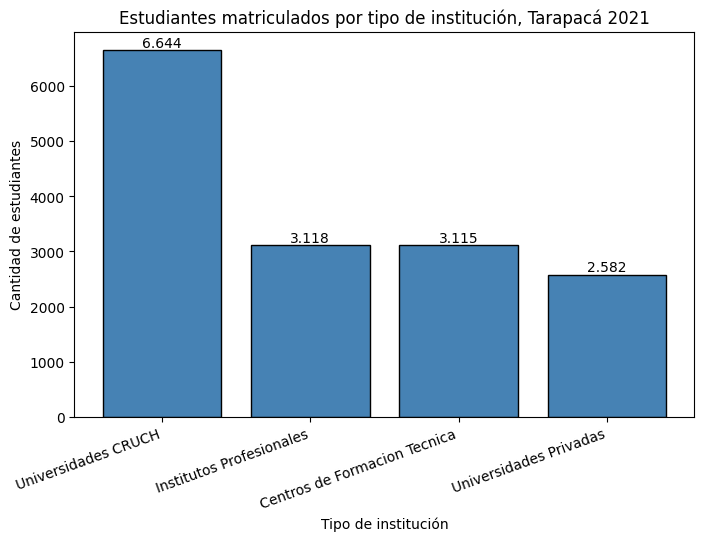

In [10]:
# Variables
categorias_tipo = tabla_1.index
f_tipo = tabla_1['Frecuencia absoluta']

# Gráfico
fig, ax = plt.subplots(figsize=(8, 5))
barras_tipo = ax.bar(categorias_tipo, f_tipo, color='steelblue', edgecolor='black')

# Personalización
ax.set_title('Estudiantes matriculados por tipo de institución, Tarapacá 2021')
ax.set_xlabel('Tipo de institución')
ax.set_ylabel('Cantidad de estudiantes')
ax.bar_label(barras_tipo, labels=[f'{v:,}'.replace(',', '.') for v in f_tipo])
plt.xticks(rotation=20, ha='right')

plt.show()

El gráfico muestra que la barra de las Universidades CRUCH es más del doble que cualquiera de las otras tres, y que las barras de Institutos Profesionales y Centros de Formación Técnica son casi iguales. La matrícula regional está concentrada en un solo tipo de institución.

**2.3 Tabla de frecuencias con dos variables: tipo de institución y nivel de la carrera**

Los porcentajes se calculan por fila, es decir, dentro de cada tipo de institución.

In [11]:
# Frecuencias absolutas cruzadas
tabla_2 = pd.crosstab(df['TIPO DE INSTITUCION'], df['NIVEL CARRERA'])
tabla_2

NIVEL CARRERA,Carreras Profesionales,Carreras Tecnicas,Magister,Postitulo
TIPO DE INSTITUCION,,,,
Centros de Formacion Tecnica,0,3115,0,0
Institutos Profesionales,3060,58,0,0
Universidades CRUCH,5322,1206,116,0
Universidades Privadas,2318,242,7,15


In [12]:
# Porcentaje por fila (dentro de cada tipo de institución)
tabla_2_pct = round(tabla_2.div(tabla_2.sum(axis=1), axis=0) * 100, 1)
tabla_2_pct

NIVEL CARRERA,Carreras Profesionales,Carreras Tecnicas,Magister,Postitulo
TIPO DE INSTITUCION,,,,
Centros de Formacion Tecnica,0.0,100.0,0.0,0.0
Institutos Profesionales,98.1,1.9,0.0,0.0
Universidades CRUCH,80.1,18.2,1.7,0.0
Universidades Privadas,89.8,9.4,0.3,0.6


Los **Centros de Formación Técnica** dictan únicamente carreras técnicas (100,0%). En los **Institutos Profesionales** predominan las carreras profesionales (98,1%), aunque también tienen carreras técnicas (1,9%).

En las **Universidades CRUCH** el 80,1% de los estudiantes está en carreras profesionales y el 18,2% en carreras técnicas; además son las únicas con una presencia relevante de **magíster** (116 estudiantes). En las **Universidades Privadas** el 89,8% está en carreras profesionales.

**2.4 Tabla de frecuencias con dos variables: tipo de institución e institución**

In [13]:
# Frecuencia absoluta por tipo e institución
cuenta_inst = df.groupby(['TIPO DE INSTITUCION', 'NOMBRE DE INSTITUCION']).size()

tabla_3 = pd.DataFrame({'Frecuencia absoluta': cuenta_inst})

# Porcentaje dentro de cada tipo de institución
tabla_3['% dentro del tipo'] = round(
    cuenta_inst / cuenta_inst.groupby(level=0).transform('sum') * 100, 1
)
tabla_3

Frecuencia absoluta  \
TIPO DE INSTITUCION          NOMBRE DE INSTITUCION                                          
Centros de Formacion Tecnica CFT DE LA REGION DE TARAPACA                             968   
                             CFT INACAP                                               933   
                             CFT SANTO TOMAS                                         1214   
Institutos Profesionales     IP INACAP                                               1769   
                             IP SANTO TOMAS                                          1349   
Universidades CRUCH          UNIVERSIDAD ARTURO PRAT                                 5449   
                             UNIVERSIDAD DE TARAPACA                                 1195   
Universidades Privadas       UNIVERSIDAD BOLIVARIANA                                  425   
                             UNIVERSIDAD SANTO TOMAS                                 1592   
                             UNIVERSIDAD TECNOLOGICA DE CHILE INACAP                  565   

                                                                      % dentro del tipo  
TIPO DE INSTITUCION          NOMBRE DE INSTITUCION                                       
Centros de Formacion Tecnica CFT DE LA REGION DE TARAPACA                          31.1  
                             CFT INACAP                                            30.0  
                             CFT SANTO TOMAS                                       39.0  
Institutos Profesionales     IP INACAP                                             56.7  
                             IP SANTO TOMAS                                        43.3  
Universidades CRUCH          UNIVERSIDAD ARTURO PRAT                               82.0  
                             UNIVERSIDAD DE TARAPACA                               18.0  
Universidades Privadas       UNIVERSIDAD BOLIVARIANA                               16.5  
                             UNIVERSIDAD SANTO TOMAS                               61.7  
                             UNIVERSIDAD TECNOLOGICA DE CHILE INACAP               21.9

La región tiene **10 instituciones**. Dentro de cada tipo hay una institución que concentra la mayoría de la matrícula:

* Universidades CRUCH: la **Universidad Arturo Prat** reúne 5.449 estudiantes, el 82,0% de su tipo. Es además la institución con más matriculados de toda la base (35,2% del total).
* Institutos Profesionales: **IP INACAP** concentra el 56,7%.
* Universidades Privadas: la **Universidad Santo Tomás** concentra el 61,7%.
* Centros de Formación Técnica: el **CFT Santo Tomás** es el mayor, con 39,0%, pero los tres CFT tienen tamaños parecidos.

## 3. Variable cuantitativa: `EDAD`

**3.1 Medidas de tendencia central**

In [14]:
media_edad = df['EDAD'].mean()
mediana_edad = df['EDAD'].median()
moda_edad = df['EDAD'].mode()

print(f'Media: {media_edad:.1f} años\nMediana: {mediana_edad:.0f} años\nModa: {moda_edad[0]} años')

Media: 26.0 años
Mediana: 24 años
Moda: 19 años


* **Media:** la edad promedio de los estudiantes matriculados en la Región de Tarapacá en 2021 es de 26,0 años.
* **Mediana:** el 50% de los estudiantes tiene a lo más 24 años.
* **Moda:** la edad más frecuente entre los estudiantes es 19 años.

Como la media es mayor que la mediana y la moda, hay estudiantes de edades altas que "tiran" el promedio hacia arriba. Por eso la **mediana** representa mejor la edad típica de un estudiante que la media.

**3.2 Percentiles**

In [15]:
p25_edad = df['EDAD'].quantile(0.25)
p50_edad = df['EDAD'].quantile(0.50)
p75_edad = df['EDAD'].quantile(0.75)

minimo_edad = df['EDAD'].min()
maximo_edad = df['EDAD'].max()
print(f'Mínimo: {minimo_edad}\nPercentil 25: {p25_edad:.0f}\nPercentil 50: {p50_edad:.0f}\nPercentil 75: {p75_edad:.0f}\nMáximo: {maximo_edad}')

Mínimo: 17
Percentil 25: 21
Percentil 50: 24
Percentil 75: 29
Máximo: 74


* El 25% de los estudiantes más jóvenes tiene entre 17 y 21 años.
* El 50% de los estudiantes tiene 24 años o menos.
* El 75% de los estudiantes tiene 29 años o menos.

Esto confirma que la mayoría de la matrícula es joven: tres de cada cuatro estudiantes tienen 29 años o menos.

**3.3 Medidas de dispersión**

In [30]:
rango_edad = maximo_edad - minimo_edad
desviacion_edad = df['EDAD'].std()
cv_edad = desviacion_edad / media_edad * 100

print(f'Rango: {rango_edad} años\nDesviación estándar: {desviacion_edad:.1f} años\nCoeficiente de variación: {cv_edad:.1f}%')

Rango: 57 años
Desviación estándar: 7.4 años
Coeficiente de variación: 28.5%


El **rango** es de 57 años (de 17 a 74 años). Es un valor grande, pero solo considera los dos extremos y no dice cómo se reparten las edades del resto.

La **desviación estándar** es de 7,4 años, es decir, en promedio las edades se alejan 7,4 años de la media. El **coeficiente de variación** es de 28,5%, lo que indica una dispersión **moderada** respecto del promedio: las edades no son homogéneas, pero tampoco extremadamente dispersas.

**3.4 Tabla de frecuencias por intervalos**

Como la variable tiene muchos valores distintos (de 17 a 74 años), se agrupa en intervalos. El número de intervalos se obtiene con la **regla de Sturges**, $k = 1 + 3{,}322 \log_{10}(n)$, y la amplitud se calcula como el rango dividido por $k$, redondeado hacia arriba.

In [17]:
# Regla de Sturges
n = len(df)
k_sturges = 1 + 3.322 * np.log10(n)
k = int(np.ceil(k_sturges))

# Amplitud de cada intervalo
amplitud = int(np.ceil(rango_edad / k))

print('Número de datos (n):', n)
print('Sturges sin redondear:', round(k_sturges, 2))
print('Número de intervalos (k):', k)
print('Amplitud de cada intervalo:', amplitud, 'años')

Número de datos (n): 15459
Sturges sin redondear: 14.92
Número de intervalos (k): 15
Amplitud de cada intervalo: 4 años


In [18]:
# Límites de los intervalos: parten en la edad mínima y avanzan de 'amplitud' en 'amplitud'
limites = np.arange(minimo_edad, minimo_edad + amplitud * k + 1, amplitud)

# Nueva columna con el intervalo de cada estudiante (intervalo cerrado a la izquierda)
df['INTERVALO EDAD'] = pd.cut(df['EDAD'], bins=limites, right=False)

# Frecuencias
fi = df['INTERVALO EDAD'].value_counts().sort_index()

tabla_4 = pd.DataFrame({
    'Frecuencia absoluta (fi)': fi,
    'Frecuencia acumulada (Fi)': fi.cumsum(),
    'Frecuencia relativa (hi) %': round(fi / n * 100, 1),
    'Frecuencia relativa acumulada (Hi) %': round((fi / n * 100).cumsum(), 1)
})


tabla_4

,Frecuencia absoluta (fi),Frecuencia acumulada (Fi),Frecuencia relativa (hi) %,Frecuencia relativa acumulada (Hi) %
INTERVALO EDAD,,,,
"[17, 21)",3232,3232,20.9,20.9
"[21, 25)",5980,9212,38.7,59.6
"[25, 29)",2172,11384,14.1,73.6
"[29, 33)",1481,12865,9.6,83.2
"[33, 37)",1018,13883,6.6,89.8
"[37, 41)",646,14529,4.2,94.0
"[41, 45)",401,14930,2.6,96.6
"[45, 49)",273,15203,1.8,98.3
"[49, 53)",140,15343,0.9,99.2


Con n = 15.459, Sturges entrega k = 15 intervalos de 4 años de amplitud.

El intervalo con mayor frecuencia es **[21, 25)**, con 5.980 estudiantes (38,7%). Los tres primeros intervalos (de 17 a 28 años) acumulan el 73,6% de la matrícula. Desde ahí las frecuencias bajan en forma sostenida: los intervalos desde los 57 años tienen menos del 1% cada uno y los últimos 3 tienen menos de 10 estudiantes. La distribución está concentrada en las edades jóvenes y tiene una cola larga hacia las edades mayores.

**3.5 Histograma**

Se utiliza un histograma porque `EDAD` es cuantitativa y está agrupada en intervalos: cada barra corresponde a un intervalo y su altura a la frecuencia absoluta.

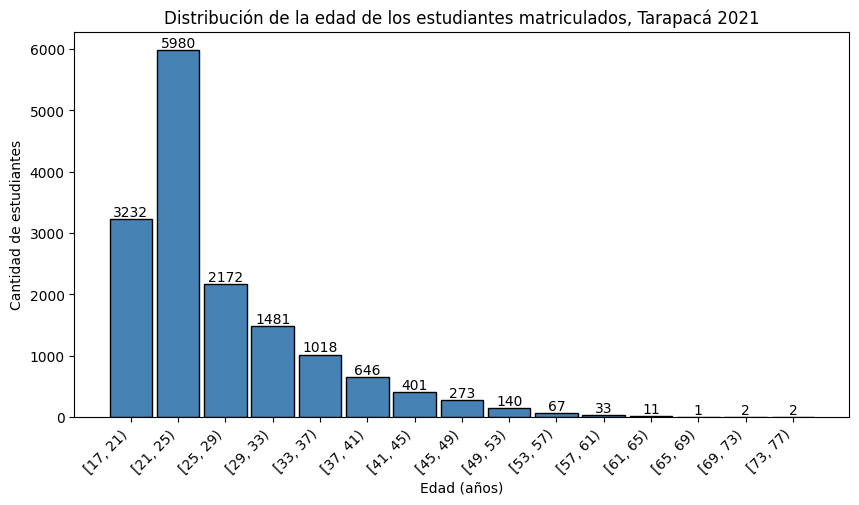

In [19]:
# Variables
categorias_edad = tabla_4.index
f_edad = tabla_4['Frecuencia absoluta (fi)']

# Gráfico
fig, ax = plt.subplots(figsize=(10, 5))
histograma_edad = ax.bar(categorias_edad.astype(str), f_edad,
                         color='steelblue', edgecolor='black', width=0.9)

# Personalización
ax.set_title('Distribución de la edad de los estudiantes matriculados, Tarapacá 2021')
ax.set_xlabel('Edad (años)')
ax.set_ylabel('Cantidad de estudiantes')
ax.bar_label(histograma_edad)
plt.xticks(rotation=45, ha='right')

plt.show()

El histograma muestra que la mayor frecuencia está en el intervalo [21, 25) y la segunda en [17, 21). A partir de los 25 años las frecuencias disminuyen de forma sostenida, formando una distribución con la mayoría de los datos a la izquierda y una cola larga hacia la derecha. El rango del histograma va de 17 a 77 años, aunque los intervalos finales tienen muy pocos casos: la edad máxima observada es 74 años.

Esto es coherente con las medidas calculadas: la moda (19 años) y la mediana (24 años) caen en los primeros intervalos, mientras que la cola de edades altas empuja la media hasta 26,0 años.

## 4. Análisis conjunto: edad según tipo de institución

**4.1 Medidas resumen de la edad por tipo de institución**

In [20]:
tabla_5 = df.groupby('TIPO DE INSTITUCION')['EDAD'].agg(
    Media='mean',
    Mediana='median',
    Moda=lambda x: x.mode()[0],
    Desviacion_estandar='std',
    Minimo='min',
    Maximo='max'
)

# Coeficiente de variación por tipo
tabla_5['CV (%)'] = tabla_5['Desviacion_estandar'] / tabla_5['Media'] * 100

round(tabla_5, 1)

,Media,Mediana,Moda,Desviacion_estandar,Minimo,Maximo,CV (%)
TIPO DE INSTITUCION,,,,,,,
Centros de Formacion Tecnica,26.8,24.0,19,8.2,18,62,30.5
Institutos Profesionales,25.9,23.0,19,7.2,18,62,28.0
Universidades CRUCH,25.3,23.0,19,6.9,17,74,27.2
Universidades Privadas,26.7,24.0,24,7.8,17,73,29.2


Las edades son parecidas en los cuatro tipos de institución. La **mediana** es de 23 años en Institutos Profesionales y Universidades CRUCH, y de 24 años en CFT y Universidades Privadas. La **moda** es 19 años en todos los tipos salvo en las Universidades Privadas, donde es 24 años.

La diferencia está en la dispersión: los **CFT** tienen la media más alta (26,8 años), la mayor desviación estándar (8,2 años) y el mayor coeficiente de variación (30,5%), es decir, son el grupo más heterogéneo en edad. Las **Universidades CRUCH** son el grupo más homogéneo (CV de 27,2%).

**4.2 Tabla cruzada: tipo de institución y rango de edad (porcentaje por fila)**

Se usa la columna `RANGO EDAD` que ya viene en la base de datos. Sus etiquetas traen un espacio al final, por lo que primero se limpian.

In [21]:
# Limpieza: las etiquetas de RANGO EDAD traen un espacio al final
df['RANGO EDAD'] = df['RANGO EDAD'].str.strip()

orden_rangos = ['15 a 19', '20 a 24', '25 a 29', '30 a 34', '35 a 39', '40 y mas']

tabla_6 = pd.crosstab(df['TIPO DE INSTITUCION'], df['RANGO EDAD'])[orden_rangos]
tabla_6_pct = round(tabla_6.div(tabla_6.sum(axis=1), axis=0) * 100, 1)
tabla_6_pct

RANGO EDAD,15 a 19,20 a 24,25 a 29,30 a 34,35 a 39,40 y mas
TIPO DE INSTITUCION,,,,,,
Centros de Formacion Tecnica,16.5,38.6,17.3,11.8,7.0,8.7
Institutos Profesionales,16.9,42.0,17.6,11.4,6.3,5.7
Universidades CRUCH,16.3,47.4,17.5,8.9,4.9,5.0
Universidades Privadas,11.1,44.2,21.6,9.9,5.0,8.1


En los cuatro tipos de institución el rango más frecuente es **20 a 24 años**, con la mayor concentración en las Universidades CRUCH (47,4%) y la menor en los CFT (38,6%).

En el otro extremo, el rango **40 y más** representa el 8,7% en los CFT, el 8,1% en las Universidades Privadas, el 5,7% en los Institutos Profesionales y solo el 5,0% en las Universidades CRUCH. Es decir, los CFT tienen proporcionalmente más estudiantes adultos.

**4.3 Diagrama de caja de la edad por tipo de institución**

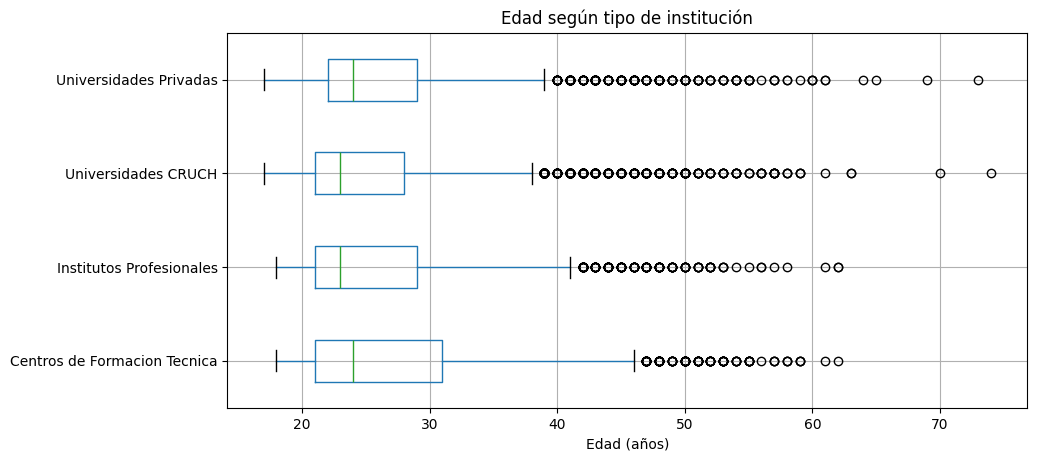

In [33]:
fig, ax = plt.subplots(figsize=(10, 5))

df.boxplot(column='EDAD', by='TIPO DE INSTITUCION', ax=ax, vert=False, )

ax.set_title('Edad según tipo de institución')
ax.set_xlabel('Edad (años)')
ax.set_ylabel('')
fig.suptitle('')

plt.show()

Las cajas (que contienen al 50% central de cada grupo) están en posiciones muy parecidas, entre los 21 y los 31 años, con la línea de la mediana casi en el mismo lugar. Lo que cambia es la cantidad de puntos a la derecha de cada caja: todos los tipos tienen estudiantes de edades altas, pero en los CFT y las Universidades Privadas la caja es un poco más ancha, en línea con su mayor desviación estándar.

## 5. Otros resúmenes

**5.1 Área del conocimiento**

In [23]:
cuenta_area = df.groupby('AREA CONOCIMIENTO').size()

tabla_7 = pd.DataFrame({
    'Frecuencia absoluta': cuenta_area,
    'Frecuencia relativa (%)': round(cuenta_area / muestra * 100, 1)
}).sort_values('Frecuencia absoluta', ascending=False)

tabla_7

,Frecuencia absoluta,Frecuencia relativa (%)
AREA CONOCIMIENTO,,
Tecnologia,4131,26.7
Administracion y Comercio,3231,20.9
Salud,2835,18.3
Educacion,2118,13.7
Ciencias Sociales,1711,11.1
Derecho,865,5.6
Arte y Arquitectura,290,1.9
Humanidades,156,1.0
Ciencias Basicas,86,0.6


El área con más estudiantes es **Tecnologia** (4.131 estudiantes, 26,7%), seguida de **Administracion y Comercio** (20,9%) y **Salud** (18,3%). Estas tres áreas reúnen el 65,9% de la matrícula. En el otro extremo, **Agropecuaria** tiene solo 36 estudiantes.

**5.2 Jornada**

In [24]:
cuenta_jornada = df.groupby('JORNADA').size()

tabla_8 = pd.DataFrame({
    'Frecuencia absoluta': cuenta_jornada,
    'Frecuencia relativa (%)': round(cuenta_jornada / muestra * 100, 1)
}).sort_values('Frecuencia absoluta', ascending=False)

tabla_8

,Frecuencia absoluta,Frecuencia relativa (%)
JORNADA,,
Diurno,9346,60.5
Vespertino,5828,37.7
Semipresencial,249,1.6
A Distancia,36,0.2


El 60,5% de los estudiantes estudia en jornada **diurna** y el 37,7% en jornada **vespertina**. Las jornadas semipresencial y a distancia son marginales (menos del 2% entre ambas). La jornada vespertina se retoma en la pregunta 2 del ítem 2 porque se relaciona con la edad.

**5.3 Año de ingreso y edad mediana según año de ingreso (2014 a 2021)**

In [25]:
cuenta_ingreso = df.groupby('AÑO INGRESO').size().loc[2014:2021]

tabla_9 = pd.DataFrame({
    'Estudiantes': cuenta_ingreso,
    'Porcentaje (%)': round(cuenta_ingreso / muestra * 100, 1),
    'Edad mediana': df.groupby('AÑO INGRESO')['EDAD'].median().loc[2014:2021]
})

tabla_9

,Estudiantes,Porcentaje (%),Edad mediana
AÑO INGRESO,,,
2014,196,1.3,27.0
2015,328,2.1,25.0
2016,618,4.0,24.0
2017,1079,7.0,24.0
2018,1739,11.2,23.0
2019,2931,19.0,23.0
2020,3578,23.1,22.0
2021,4744,30.7,22.0


La base corresponde a los matriculados en 2021, así que incluye tanto a quienes ingresaron ese año como a quienes siguen estudiando desde años anteriores. Los ingresos de 2019, 2020 y 2021 concentran el 72,8% de la matrícula. La edad mediana sube a medida que el año de ingreso es más antiguo (de 22 años para los que entraron en 2021 a 27 años para los de 2014), lo que es esperable porque esos estudiantes llevan más años en la carrera.

---
# Ítem 2. Preguntas de investigación

Para las preguntas sobre aranceles se trabaja con **programas** y no con estudiantes: un programa es una carrera dictada por una institución en una jornada y con un tipo de plan determinado. Si se contara por estudiante, una carrera masiva pesaría más que una carrera pequeña aunque tuvieran el mismo arancel.

In [26]:
columnas_programa = ['NOMBRE CARRERA', 'NOMBRE DE INSTITUCION', 'TIPO DE INSTITUCION',
                     'NIVEL DE ESTUDIO CARRERA', 'NIVEL CARRERA', 'AREA CONOCIMIENTO', 'JORNADA', 'TIPO PLAN CARRERA']

# Verificamos que cada programa tenga un único arancel
verificacion = df.groupby(columnas_programa)['VALOR ARANCEL (PESOS)'].nunique()
verificacion.value_counts()

,count
VALOR ARANCEL (PESOS),
1,261


In [36]:
# Tabla de programas: arancel, cantidad de estudiantes y duración
programas = df.groupby(columnas_programa).agg(
    arancel=('VALOR ARANCEL (PESOS)', 'first'),
    estudiantes=('ID', 'count'),
    semestres=('DURACION TOTAL CARRERA (SEMESTRES)', 'first')
).reset_index()

print('Cantidad de programas:', len(programas))
programas.head()

Cantidad de programas: 261


,NOMBRE CARRERA,NOMBRE DE INSTITUCION,TIPO DE INSTITUCION,NIVEL DE ESTUDIO CARRERA,NIVEL CARRERA,AREA CONOCIMIENTO,JORNADA,TIPO PLAN CARRERA,arancel,estudiantes,semestres
0,ADMINISTRACION DE EMPRESAS,CFT INACAP,Centros de Formacion Tecnica,Pregrado,Carreras Tecnicas,Administracion y Comercio,Diurno,Plan Regular,2040000,78,4
1,ADMINISTRACION DE EMPRESAS,CFT INACAP,Centros de Formacion Tecnica,Pregrado,Carreras Tecnicas,Administracion y Comercio,Vespertino,Plan Regular,2040000,93,4
2,ADMINISTRACION GASTRONOMICA INTERNACIONAL,IP INACAP,Institutos Profesionales,Pregrado,Carreras Profesionales,Administracion y Comercio,Diurno,Plan Regular,2570000,184,8
3,AGRONOMIA,UNIVERSIDAD ARTURO PRAT,Universidades CRUCH,Pregrado,Carreras Profesionales,Agropecuaria,Diurno,Plan Regular,2933000,24,10
4,ANALISTA PROGRAMADOR,CFT INACAP,Centros de Formacion Tecnica,Pregrado,Carreras Tecnicas,Tecnologia,Diurno,Plan Regular,2064000,72,4


Todos los programas tienen un único arancel (la verificación entrega 1 en los 261 casos), por lo que se puede usar el arancel del programa directamente.

## Pregunta 1. ¿Hay áreas del conocimiento donde las carreras sean más caras?

**Criterio diseñado**

1. **Unidad de análisis:** el programa, no el estudiante.
2. **Programas comparables:** solo **carreras profesionales** con arancel mayor que 0. Se dejan fuera las carreras técnicas (más cortas y baratas, y no todas las áreas las tienen), los magísteres y los postítulos (otro nivel de formación), para no comparar cosas distintas.
3. **Medida de comparación:** la **mediana** del arancel anual por área, porque no se ve afectada por uno o dos programas muy caros. Se calcula además la razón entre la mediana del área y la mediana global (1,00 significa igual al conjunto).
4. **Verificación:** se repite el cálculo incluyendo carreras técnicas y a nivel de estudiante, para ver si el orden de las áreas se mantiene.

In [37]:
# Programas profesionales con arancel registrado
prof = programas[(programas['NIVEL CARRERA'] == 'Carreras Profesionales') & (programas['arancel'] > 0)]

mediana_global = prof['arancel'].median()
print(f'Programas profesionales: {len(prof)}  |  Mediana global del arancel: ${mediana_global:,.0f}')

Programas profesionales: 163  |  Mediana global del arancel: $2,165,000


In [38]:
tabla_10 = prof.groupby('AREA CONOCIMIENTO').agg(
    programas=('arancel', 'size'),
    estudiantes=('estudiantes', 'sum'),
    mediana=('arancel', 'median'),
    minimo=('arancel', 'min'),
    maximo=('arancel', 'max')
).sort_values('mediana', ascending=False)

tabla_10['razon vs mediana global'] = round(tabla_10['mediana'] / mediana_global, 2)
tabla_10

,programas,estudiantes,mediana,minimo,maximo,razon vs mediana global
AREA CONOCIMIENTO,,,,,,
Salud,14,1867,3297500.0,2552000,4047000,1.52
Derecho,5,781,3275000.0,2350000,3995000,1.51
Agropecuaria,1,24,2933000.0,2933000,2933000,1.35
Ciencias Basicas,1,17,2481000.0,2481000,2481000,1.15
Arte y Arquitectura,3,264,2258000.0,2258000,2987000,1.04
Tecnologia,67,3156,2166000.0,1700000,3805000,1.00
Administracion y Comercio,32,1902,2112000.0,1240000,3533000,0.98
Educacion,23,1075,2106000.0,1528000,2857000,0.97
Ciencias Sociales,15,1536,2086000.0,1644000,3559000,0.96


**Salud** tiene la mediana de arancel más alta, $3.297.500, equivalente a 1,52 veces la mediana global de $2.165.000. Le sigue **Derecho** con $3.275.000 (1,51 veces).

**Tecnologia** es el área con más programas (67) y su mediana de $2.166.000 coincide con la global (razón 1,00). Las áreas más baratas son **Educacion** ($2.106.000) y **Humanidades** ($1.998.300).

Las áreas **Agropecuaria, Ciencias Basicas, Humanidades** tienen menos de tres programas profesionales, así que su mediana es en realidad el arancel de uno o dos programas y no permite concluir sobre el área.

**Diagrama de caja del arancel por área**

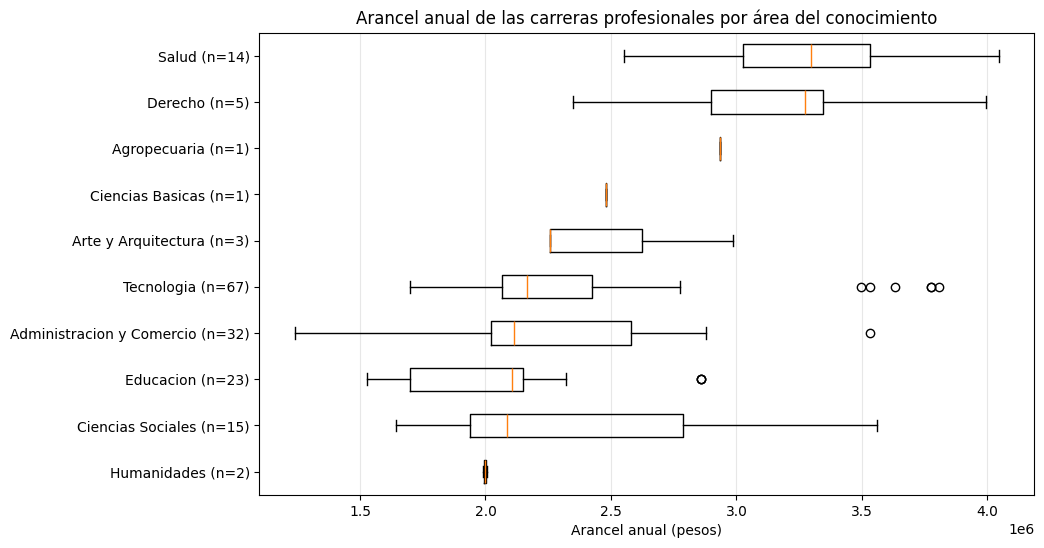

In [43]:
# Áreas ordenadas de menor a mayor mediana
orden_areas = tabla_10.sort_values('mediana').index

# Lista con los aranceles de cada área, en ese orden
datos_areas = [prof[prof['AREA CONOCIMIENTO'] == area]['arancel'] for area in orden_areas]
etiquetas_areas = [f'{area} (n={tabla_10.loc[area, "programas"]})' for area in orden_areas]

fig, ax = plt.subplots(figsize=(10, 6))
ax.boxplot(datos_areas, vert=False)

ax.set_yticks(range(1, len(orden_areas) + 1))
ax.set_yticklabels(etiquetas_areas)
ax.set_title('Arancel anual de las carreras profesionales por área del conocimiento')
ax.set_xlabel('Arancel anual (pesos)')
ax.grid(axis='x', alpha=0.3)

plt.show()

En el diagrama, las cajas de **Salud** y **Derecho** están claramente desplazadas a la derecha respecto de las demás áreas, lo que confirma que sus aranceles son más altos. Salud es además el área con mayor recorrido: va desde $2.552.000 hasta $4.047.000, el arancel más alto de todo el pregrado. Las áreas con n = 1 aparecen solo como una línea.

**Verificación con otros criterios**

In [44]:
# A: mediana por área usando programas profesionales (criterio principal)
s_A = prof.groupby('AREA CONOCIMIENTO')['arancel'].median()

# B: mediana por área incluyendo carreras técnicas
s_B = programas[
    (programas['NIVEL CARRERA'].isin(['Carreras Profesionales', 'Carreras Tecnicas'])) &
    (programas['arancel'] > 0)
].groupby('AREA CONOCIMIENTO')['arancel'].median()

# C: mediana por área contando por estudiante (carreras profesionales)
s_C = df[
    (df['NIVEL CARRERA'] == 'Carreras Profesionales') & (df['VALOR ARANCEL (PESOS)'] > 0)
].groupby('AREA CONOCIMIENTO')['VALOR ARANCEL (PESOS)'].median()

tabla_11 = pd.DataFrame({
    'A: programas profesionales': s_A,
    'B: incluye tecnicas': s_B,
    'C: por estudiante': s_C
}).loc[s_A.sort_values(ascending=False).index]

tabla_11

,A: programas profesionales,B: incluye tecnicas,C: por estudiante
AREA CONOCIMIENTO,,,
Salud,3297500.0,2736000.0,3217000.0
Derecho,3275000.0,3086500.0,3275000.0
Agropecuaria,2933000.0,2933000.0,2933000.0
Ciencias Basicas,2481000.0,1544000.0,2481000.0
Arte y Arquitectura,2258000.0,2258000.0,2987000.0
Tecnologia,2166000.0,2164000.0,2426000.0
Administracion y Comercio,2112000.0,2076500.0,2474000.0
Educacion,2106000.0,1700000.0,2106000.0
Ciencias Sociales,2086000.0,1984500.0,2719000.0


### Respuesta a la pregunta 1

**Sí.** Con el criterio principal (A), **Salud** ($3.297.500) y **Derecho** ($3.275.000) son las áreas más caras, alrededor de 1,5 veces la mediana global.

Al incluir las carreras técnicas (B), Derecho queda primero ($3.086.500) y Salud baja a $2.736.000, porque Salud tiene muchas carreras técnicas de menor arancel. Al contar por estudiante (C), Derecho ($3.275.000) y Salud ($3.217.000) siguen siendo las dos áreas más caras.

Por lo tanto, independiente del criterio, **Derecho y Salud son las áreas donde las carreras son más caras**, mientras que **Educación, Humanidades y Ciencias Sociales** están bajo la mediana global en todos los criterios.

## Pregunta 2. ¿Qué influencia tiene la edad en el tipo de institución a la que ingresan los estudiantes?

**Criterio diseñado**

1. Comparar la **media, mediana, moda y dispersión** de la edad en cada tipo de institución (tabla 5 de la sección 4).
2. Agrupar la edad en cuatro tramos y construir una **tabla cruzada** con porcentajes por tipo de institución, para ver en qué tramos se concentra cada tipo.
3. Revisar la **jornada**, porque puede explicar parte de las diferencias de edad.

**2.1 Edad por tipo de institución**

Se retoma la tabla 5 de la sección 4.

In [45]:
round(tabla_5, 1)

,Media,Mediana,Moda,Desviacion_estandar,Minimo,Maximo,CV (%)
TIPO DE INSTITUCION,,,,,,,
Centros de Formacion Tecnica,26.8,24.0,19,8.2,18,62,30.5
Institutos Profesionales,25.9,23.0,19,7.2,18,62,28.0
Universidades CRUCH,25.3,23.0,19,6.9,17,74,27.2
Universidades Privadas,26.7,24.0,24,7.8,17,73,29.2


Las medianas van de 23 a 24 años y las medias de 25,3 a 26,8 años: la edad "típica" es casi la misma en los cuatro tipos. Lo que cambia es la dispersión, mayor en los CFT (CV de 30,5%) y menor en las Universidades CRUCH (CV de 27,2%).

**2.2 Tramos de edad por tipo de institución**

In [46]:
# Cuatro tramos de edad
df['TRAMO EDAD'] = pd.cut(df['EDAD'], bins=[16, 19, 24, 29, 200],
                          labels=['17 a 19', '20 a 24', '25 a 29', '30 o mas'])

tabla_12 = pd.crosstab(df['TIPO DE INSTITUCION'], df['TRAMO EDAD'])
tabla_12_pct = round(tabla_12.div(tabla_12.sum(axis=1), axis=0) * 100, 1)
tabla_12_pct

TRAMO EDAD,17 a 19,20 a 24,25 a 29,30 o mas
TIPO DE INSTITUCION,,,,
Centros de Formacion Tecnica,16.5,38.6,17.3,27.6
Institutos Profesionales,16.9,42.0,17.6,23.4
Universidades CRUCH,16.3,47.4,17.5,18.8
Universidades Privadas,11.1,44.2,21.6,23.1


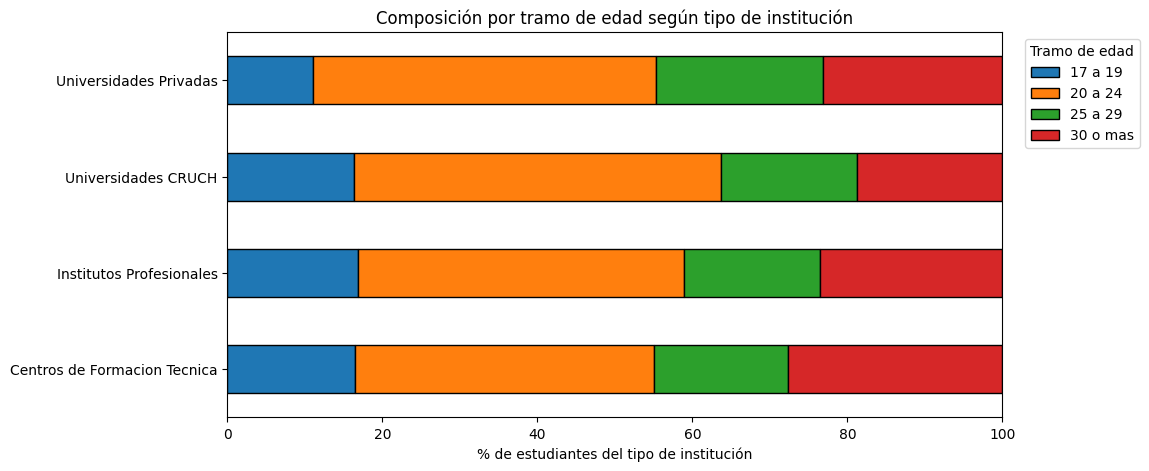

In [47]:
# Gráfico de barras apiladas al 100 % con los tramos de edad
fig, ax = plt.subplots(figsize=(10, 5))
tabla_12_pct.plot(kind='barh', stacked=True, ax=ax, edgecolor='black')

ax.set_title('Composición por tramo de edad según tipo de institución')
ax.set_xlabel('% de estudiantes del tipo de institución')
ax.set_ylabel('')
ax.set_xlim(0, 100)
ax.legend(title='Tramo de edad', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.show()

Los estudiantes de **24 años o menos** son el 63,7% en las Universidades CRUCH, el 58,9% en los Institutos Profesionales, el 55,1% en los CFT y el 55,3% en las Universidades Privadas.

Los estudiantes de **30 años o más** son el 27,6% en los CFT, el 23,4% en los IP, el 23,1% en las Universidades Privadas y solo el 18,8% en las Universidades CRUCH. Las Universidades CRUCH son el tipo más "joven" y los CFT el que tiene más estudiantes adultos.

**2.3 Jornada y edad**

In [48]:
tabla_13 = df.groupby(['TIPO DE INSTITUCION', 'JORNADA'])['EDAD'].agg(
    Media='mean', Mediana='median', Estudiantes='count'
)
round(tabla_13, 1)

Media  Mediana  Estudiantes
TIPO DE INSTITUCION          JORNADA                                    
Centros de Formacion Tecnica Diurno           24.4     22.0         1773
                             Vespertino       29.9     28.0         1342
Institutos Profesionales     Diurno           23.2     22.0         1536
                             Vespertino       28.5     27.0         1582
Universidades CRUCH          A Distancia      38.6     39.0           36
                             Diurno           23.3     22.0         4523
                             Semipresencial   39.5     36.5           12
                             Vespertino       29.6     28.0         2073
Universidades Privadas       Diurno           23.2     23.0         1514
                             Semipresencial   30.9     29.0          237
                             Vespertino       31.8     29.0          831

In [49]:
# Porcentaje de cada jornada dentro de cada tipo de institución
tabla_14 = pd.crosstab(df['TIPO DE INSTITUCION'], df['JORNADA'])
round(tabla_14.div(tabla_14.sum(axis=1), axis=0) * 100, 1)

JORNADA,A Distancia,Diurno,Semipresencial,Vespertino
TIPO DE INSTITUCION,,,,
Centros de Formacion Tecnica,0.0,56.9,0.0,43.1
Institutos Profesionales,0.0,49.3,0.0,50.7
Universidades CRUCH,0.5,68.1,0.2,31.2
Universidades Privadas,0.0,58.6,9.2,32.2


En todos los tipos de institución los estudiantes **vespertinos son mayores** que los diurnos: la mediana general es de 22 años en jornada diurna y de 28 años en jornada vespertina. La jornada vespertina pesa más en los Institutos Profesionales (50,7%) y en los CFT (43,1%) que en las Universidades CRUCH (31,2%) y Privadas (32,2%).

### Respuesta a la pregunta 2

La edad **influye poco** en el tipo de institución: la mediana de edad es prácticamente la misma en los cuatro tipos (23 a 24 años) y en todos el tramo más frecuente es 20 a 24 años.

La diferencia aparece en los extremos. Las **Universidades CRUCH** concentran a los estudiantes más jóvenes (63,7% tiene 24 años o menos) y tienen la menor proporción de mayores de 30 (18,8%). Los **CFT** son el tipo con más estudiantes adultos (27,6% tiene 30 años o más) y la mayor dispersión de edades.

Parte de esta diferencia se explica por la **jornada**: los estudiantes vespertinos son mayores, y la jornada vespertina es más común en CFT e Institutos Profesionales que en las universidades. Con una base de datos descriptiva no se puede afirmar que la edad "cause" la elección, solo que los estudiantes adultos están más presentes en la formación técnica y en la jornada vespertina.

## Pregunta 3. ¿Hay carreras cuyo arancel sea sustantivamente más caro que la mayoría? ¿Qué explicación pueden encontrar?

**Criterio diseñado**

1. **Unidad de análisis:** el programa, considerando todos los niveles (pregrado, postgrado y postítulo) con arancel mayor que 0.
2. **Definición de "sustantivamente más caro":** programas cuyo arancel supera el **percentil 95** de los aranceles de los programas, es decir, el 5% de programas más caros de la región. Para cada uno se calcula cuántas veces supera la **mediana**.
3. **Explicación:** se revisa qué tienen en común esos programas (institución, nivel de estudio, área) y se compara la mediana del arancel según nivel de estudio, tipo de institución y duración.
4. **Contexto regional:** se relaciona con la oferta de instituciones de la Región de Tarapacá.

In [50]:
# Programas con arancel registrado (todos los niveles)
prog_arancel = programas[programas['arancel'] > 0].copy()

mediana_prog = prog_arancel['arancel'].median()
p95_prog = prog_arancel['arancel'].quantile(0.95)

print(f'Programas con arancel: {len(prog_arancel)}')
print(f'Mediana del arancel: ${mediana_prog:,.0f}')
print(f'Percentil 95 del arancel: ${p95_prog:,.0f}')

Programas con arancel: 260
Mediana del arancel: $2,112,000
Percentil 95 del arancel: $3,534,300


In [51]:
# Programas sobre el percentil 95
caros = prog_arancel[prog_arancel['arancel'] > p95_prog].sort_values('arancel', ascending=False).copy()
caros['veces la mediana'] = round(caros['arancel'] / mediana_prog, 2)

print('Cantidad de programas sobre el percentil 95:', len(caros))
caros[['NOMBRE CARRERA', 'NOMBRE DE INSTITUCION', 'NIVEL DE ESTUDIO CARRERA',
       'AREA CONOCIMIENTO', 'JORNADA', 'arancel', 'veces la mediana']]

Cantidad de programas sobre el percentil 95: 13


,NOMBRE CARRERA,NOMBRE DE INSTITUCION,NIVEL DE ESTUDIO CARRERA,AREA CONOCIMIENTO,JORNADA,arancel,veces la mediana
144,MAGISTER EN GERENCIA PUBLICA,UNIVERSIDAD ARTURO PRAT,Postgrado,Ciencias Sociales,Vespertino,4847000,2.29
141,MAGISTER EN DIRECCION Y GESTION DE RECURSOS HU...,UNIVERSIDAD ARTURO PRAT,Postgrado,Administracion y Comercio,Vespertino,4847000,2.29
148,MAGISTER EN RELACIONES INTERNACIONALES Y ESTUD...,UNIVERSIDAD ARTURO PRAT,Postgrado,Ciencias Sociales,Diurno,4216000,2.00
139,MAGISTER EN BIOTECNOLOGIA,UNIVERSIDAD ARTURO PRAT,Postgrado,Tecnologia,Vespertino,4200000,1.99
157,ODONTOLOGIA,UNIVERSIDAD ARTURO PRAT,Pregrado,Salud,Diurno,4047000,1.92
140,MAGISTER EN CIENCIAS CON MENCION EN FISICA TEO...,UNIVERSIDAD ARTURO PRAT,Postgrado,Ciencias Basicas,Diurno,4042600,1.91
20,DERECHO,UNIVERSIDAD DE TARAPACA,Pregrado,Derecho,Diurno,3995000,1.89
50,INGENIERIA CIVIL INDUSTRIAL,UNIVERSIDAD DE TARAPACA,Pregrado,Tecnologia,Diurno,3805000,1.80
44,INGENIERIA CIVIL ELECTRICA,UNIVERSIDAD DE TARAPACA,Pregrado,Tecnologia,Diurno,3775000,1.79
45,INGENIERIA CIVIL ELECTRICA CON MENCION EN CONT...,UNIVERSIDAD DE TARAPACA,Pregrado,Tecnologia,Diurno,3775000,1.79


Hay **13 programas** sobre el percentil 95 ($3.534.300). Los más caros son **MAGISTER EN DIRECCION Y GESTION DE RECURSOS HUMANOS** (UNIVERSIDAD ARTURO PRAT) y **MAGISTER EN GERENCIA PUBLICA** (UNIVERSIDAD ARTURO PRAT), con $4.847.000, 2,29 veces la mediana de $2.112.000.

Lo que tienen en común:

* **Tipo de institución:** todos se dictan en universidades; no hay ninguno de Institutos Profesionales ni de CFT.
* **Institución:** 6 de UNIVERSIDAD ARTURO PRAT, 6 de UNIVERSIDAD DE TARAPACA, 1 de UNIVERSIDAD SANTO TOMAS.
* **Nivel de estudio:** 5 son **magíster** (postgrado) y 8 son carreras profesionales de pregrado; 8 de esas 8 carreras duran 10 semestres o más.
* **Área de los de pregrado:** Tecnologia, Salud, Derecho, Ciencias Sociales.

In [52]:
# Mediana del arancel según nivel de estudio
tabla_15 = prog_arancel.groupby('NIVEL DE ESTUDIO CARRERA')['arancel'].agg(Programas='size', Mediana='median', Maximo='max')
tabla_15

,Programas,Mediana,Maximo
NIVEL DE ESTUDIO CARRERA,,,
Postgrado,10,3643800.0,4847000
Postitulo,1,999840.0,999840
Pregrado,249,2109000.0,4047000


In [53]:
# Mediana del arancel según tipo de institución
tabla_16 = prog_arancel.groupby('TIPO DE INSTITUCION')['arancel'].agg(Programas='size', Mediana='median', Maximo='max').sort_values('Mediana', ascending=False)
tabla_16

,Programas,Mediana,Maximo
TIPO DE INSTITUCION,,,
Universidades CRUCH,83,2608000.0,4847000
Universidades Privadas,60,2112000.0,3749000
Institutos Profesionales,57,2070000.0,2570000
Centros de Formacion Tecnica,60,2056000.0,2570000


In [54]:
# Mediana del arancel según duración total de la carrera (semestres)
tabla_17 = prog_arancel.groupby('semestres')['arancel'].agg(Programas='size', Mediana='median')
tabla_17

,Programas,Mediana
semestres,,
1,1,999840.0
2,2,2259000.0
3,2,3375000.0
4,44,2170000.0
5,58,1499400.0
6,1,1640000.0
7,1,1700000.0
8,75,2112000.0
9,18,2126000.0


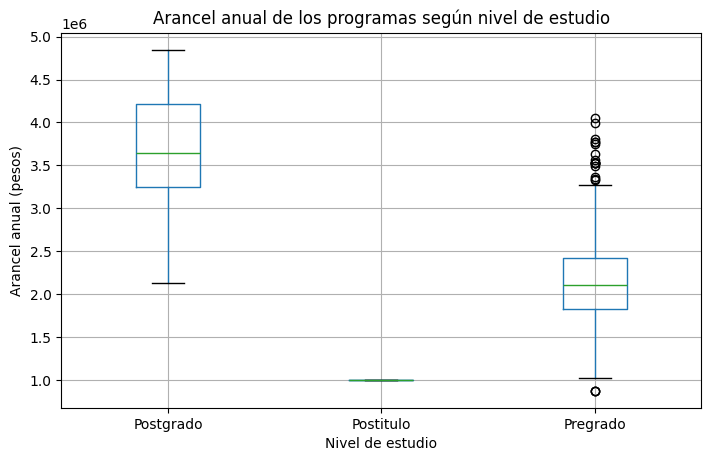

In [55]:
fig, ax = plt.subplots(figsize=(8, 5))
prog_arancel.boxplot(column='arancel', by='NIVEL DE ESTUDIO CARRERA', ax=ax)

ax.set_title('Arancel anual de los programas según nivel de estudio')
ax.set_xlabel('Nivel de estudio')
ax.set_ylabel('Arancel anual (pesos)')
fig.suptitle('')

plt.show()

* **Nivel de estudio:** los programas de **postgrado** tienen una mediana de $3.643.800, muy por sobre los $2.109.000 del pregrado. En el diagrama de caja, la caja de postgrado está completa sobre la mediana de pregrado.
* **Tipo de institución:** las universidades tienen aranceles más altos (mediana de $2.608.000 en Universidades CRUCH) que los Institutos Profesionales ($2.070.000) y los CFT ($2.056.000).
* **Duración:** los programas de 10 o más semestres tienen medianas sobre $2.736.000, mientras que los de 4 o 5 semestres (carreras técnicas) están bajo $2.170.000.

### Respuesta a la pregunta 3

**Sí.** Hay 13 programas cuyo arancel supera el percentil 95 y llegan hasta 2,29 veces la mediana regional. Comparten tres características: **todos se dictan en universidades**, los más caros son **magísteres** (5 de los 13) y los de pregrado son **carreras largas** (8 de las 8 duran 10 semestres o más) de las áreas Tecnologia, Salud, Derecho, Ciencias Sociales. Estas coinciden con lo visto en la pregunta 1, donde Salud y Derecho resultaron las áreas más caras.

El nivel de estudio es la explicación más clara: la mediana del postgrado ($3.643.800) es 1,73 veces la del pregrado ($2.109.000). Le siguen el tipo de institución (las universidades tienen aranceles más altos que IP y CFT) y la duración (las carreras de 10 o más semestres son más caras que las técnicas de 4 o 5). En el caso de **Odontología**, la carrera de pregrado más cara, se suma que requiere clínicas y equipamiento propio para su dictado.

**Contexto regional.** La Región de Tarapacá tiene solo 10 instituciones de educación superior y toda la oferta está en la provincia de Iquique (14.491 estudiantes en Iquique y 968 en Alto Hospicio). Los programas más caros se concentran en tres universidades. La **Universidad Arturo Prat**, universidad estatal con sede principal en Iquique, concentra el 35,2% de la matrícula regional y prácticamente toda la oferta de postgrado (116 de los 123 estudiantes de postgrado), por lo que los magísteres más caros son suyos. La **Universidad de Tarapacá**, también estatal, dicta en Iquique las ingenierías civiles y carreras de salud de mayor arancel del pregrado. Con pocas instituciones y toda la oferta en una provincia, un estudiante que quiera una de estas carreras en la región tiene muy pocas alternativas de precio.

---
# Conclusiones

1. La matrícula de educación superior de Tarapacá en 2021 (15.459 estudiantes) se concentra en las **Universidades CRUCH** (43,0%), y dentro de ellas en la Universidad Arturo Prat.
2. Los estudiantes son mayoritariamente **jóvenes**: mediana de 24 años, moda de 19 años y el 75% con 29 años o menos, con una cola de estudiantes adultos que lleva la media a 26,0 años y el coeficiente de variación a 28,5%.
3. La **edad influye poco** en el tipo de institución; los CFT y la jornada vespertina concentran a los estudiantes adultos.
4. **Derecho y Salud** son las áreas con carreras más caras, cerca de 1,5 veces la mediana regional.
5. Los programas **sustantivamente más caros** (sobre el percentil 95) son todos universitarios: los magísteres de la Universidad Arturo Prat y carreras largas de Salud, Derecho e Ingeniería Civil, lo que se explica por el nivel de estudio, el tipo de institución y la duración.